# Baseline model: Linear Regression

Predict `ClosePrice` for single-family homes from Dataset A (`02b_preprocessing_dataset_a.ipynb`).

Two things are picked here:

- **The training window X.** Train on the X months right before an evaluation month.
- **The two linear-regression experiments from the procedures doc:** log target (`log1p(ClosePrice)`, with predictions converted back to dollars before scoring) and log `LivingArea` / `LotSizeSquareFeet`.

Both are chosen on a rolling backtest over the 6 validation months 2025-10 to 2026-03. The test month, 2026-04, is held out and never scored.

Every metric is on the dollar scale. Besides R², MAE and MAPE (mean absolute % error) are reported because they're easier to read for a price model, plus the median absolute % error and the share of homes within 10%.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

from idx_exchange_data_science import dataset_a as da
from idx_exchange_data_science.modeling import backtest, build_model, final_estimator, fit_window, median_ape_by
from idx_exchange_data_science.splits import validation_months

pd.set_option("display.float_format", "{:,.4f}".format)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

WINDOWS = [1, 2, 3, 6, 9, 12, 18]
EVAL_MONTHS = validation_months("2026-04", n_months=6)  # 2025-10 to 2026-03; 2026-04 is the held-out test month
METRICS = ["r2", "mae", "mape", "median_ape", "within_10pct"]
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)

df = da.load_clean("../data/processed/CRMLSSoldDatasetA.csv")
df.shape

(309019, 20)

## 1. Model variants
Every variant has the same pipeline: the Dataset A preprocessor (`da.make_preprocessor`) → `StandardScaler` → `LinearRegression`. Scaling doesn't change OLS predictions. It only puts the coefficients on a comparable scale.

In [2]:
log_features = da.make_preprocessor(log_features=True)
models = {
    "LR": build_model(LinearRegression(), scale=True),
    "LR + log features": build_model(LinearRegression(), log_features, scale=True),
    "LR + log target": build_model(LinearRegression(), scale=True, log_target=True),
    "LR + log target + log features": build_model(LinearRegression(), log_features, scale=True, log_target=True),
}

## 2. Choosing the training window X
Each variant is fit on the X months before each validation month and scored on that month. That gives 7 windows × 6 months. The largest window that fits before 2025-10 is 21 months, so 18 is the longest one tried.

In [3]:
runs = {x: backtest(models, df, EVAL_MONTHS, train_months=x) for x in WINDOWS}
results = pd.concat([scores.assign(X=x) for x, (scores, _) in runs.items()], ignore_index=True)
mean_r2 = results.pivot_table(index="X", columns="model", values="r2", aggfunc="mean")[list(models)]
mean_r2

model,LR,LR + log features,LR + log target,LR + log target + log features
X,,,,
1,0.7604,0.7336,0.4565,0.7771
2,0.7704,0.7449,0.5075,0.7845
3,0.7778,0.7525,0.5137,0.7906
6,0.7834,0.7583,0.5252,0.7917
9,0.7863,0.7614,0.5320,0.7968
12,0.7874,0.7627,0.5476,0.7996
18,0.7894,0.7652,0.5635,0.8007


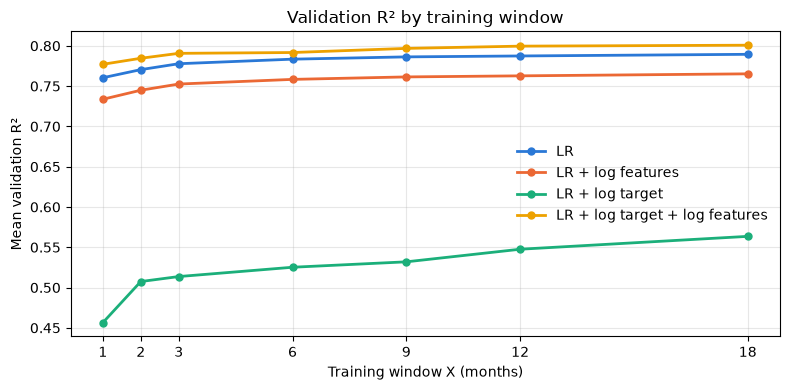

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for color, name in zip(COLORS, models):
    ax.plot(mean_r2.index, mean_r2[name], marker="o", markersize=5, linewidth=2, color=color, label=name)
ax.set(xlabel="Training window X (months)", ylabel="Mean validation R²", title="Validation R² by training window",
       xticks=WINDOWS)
ax.grid(alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()

Month-to-month spread matters too. If one X only wins by a fraction of the spread, it isn't really better.

In [5]:
results.groupby(["model", "X"])["r2"].agg(["mean", "std", "min"]).unstack("model").swaplevel(axis=1)[list(models)]

model     LR               LR + log features               LR + log target  \
        mean    std    min              mean    std    min            mean   
X                                                                            
1     0.7604 0.0135 0.7437            0.7336 0.0193 0.7117          0.4565   
2     0.7704 0.0117 0.7589            0.7449 0.0164 0.7228          0.5075   
3     0.7778 0.0129 0.7663            0.7525 0.0172 0.7325          0.5137   
6     0.7834 0.0116 0.7700            0.7583 0.0158 0.7359          0.5252   
9     0.7863 0.0104 0.7759            0.7614 0.0142 0.7433          0.5320   
12    0.7874 0.0101 0.7776            0.7627 0.0141 0.7455          0.5476   
18    0.7894 0.0090 0.7802            0.7652 0.0121 0.7543          0.5635   

model                LR + log target + log features                
         std     min                           mean    std    min  
X                                                                  
1     0.3505 -0.2224                         0.7771 0.0121 0.7617  
2     0.2343  0.0880                         0.7845 0.0144 0.7674  
3     0.2616  0.0239                         0.7906 0.0138 0.7738  
6     0.2233  0.1395                         0.7917 0.0226 0.7510  
9     0.2182  0.1532                         0.7968 0.0175 0.7666  
12    0.2338  0.1463                         0.7996 0.0153 0.7733  
18    0.2142  0.2018                         0.8007 0.0148 0.7771

In [6]:
best_x = mean_r2.idxmax()
best_x

model
LR                                18
LR + log features                 18
LR + log target                   18
LR + log target + log features    18
dtype: int64

**Observations**
- **Longer windows help every variant.** Validation R² is still creeping up at 18 months, the longest window that fits before the validation months, so X = 18 is chosen for all four. Past 6 months the gains are small: +0.006 for plain LR between 6 and 18, which is less than its month-to-month standard deviation (about 0.01). A shorter window would cost little.
- **A log target on its own is unstable.** It has the worst mean and swings wildly from month to month, and one month even has a negative R². Without logging the features, a linear term in log price turns extreme values (lot size has no upper limit in Dataset A) into multiplicative effects, and converting back to dollars blows those predictions up.
- **Logging both the target and the features** gives the best and the most stable validation scores, so that variant is the baseline.

## 3. Choosing the baseline
Each variant at its chosen X, averaged over the 6 validation months. The baseline is the variant with the best mean validation R².

In [7]:
chosen = results[results["X"] == results["model"].map(best_x)]
summary = chosen.groupby("model")[METRICS].mean().loc[list(models)]
summary.insert(0, "X", best_x)
baseline_name = summary["r2"].idxmax()
summary

,X,r2,mae,mape,median_ape,within_10pct
model,,,,,,
LR,18,0.7894,"260,547.8712",0.2533,0.1885,0.2852
LR + log features,18,0.7652,"276,637.7999",0.2753,0.2017,0.2646
LR + log target,18,0.5635,"212,980.2275",0.1608,0.1172,0.4370
LR + log target + log features,18,0.8007,"207,042.7974",0.1609,0.1196,0.4291


**Observations**
- **The baseline's mean validation R² is 0.801** (MAE about \$207K, mean absolute % error 16.1%, median 12.0%, 43% of homes within 10%).
- Next to plain LR, the log variant gains only 0.011 R² but cuts the mean % error from 25.3% to 16.1%. R² on dollars is driven mostly by the expensive homes, while the % errors weight every home equally.

## 4. What the baseline learned
Standardized coefficients of the baseline fit on the 18 months before the last validation month (2026-03): the change in the prediction (in log dollars if the target is logged) for a one-standard-deviation change in the feature.

In [8]:
baseline = final_estimator(fit_window(models[baseline_name], df, EVAL_MONTHS[-1], best_x[baseline_name]))
coefficients = pd.Series(baseline.coef_, index=baseline.feature_names_in_)
coefficients.sort_values(key=abs, ascending=False).to_frame("coefficient")

,coefficient
PostalCode,0.3275
LivingArea,0.1707
Longitude,-0.1000
City,0.0903
Latitude,-0.0884
BathroomsTotalInteger,0.0760
CountyOrParish,0.0441
PropertyAge,0.0385
LotSizeSquareFeet,0.0292
PoolPrivateYN,0.0207


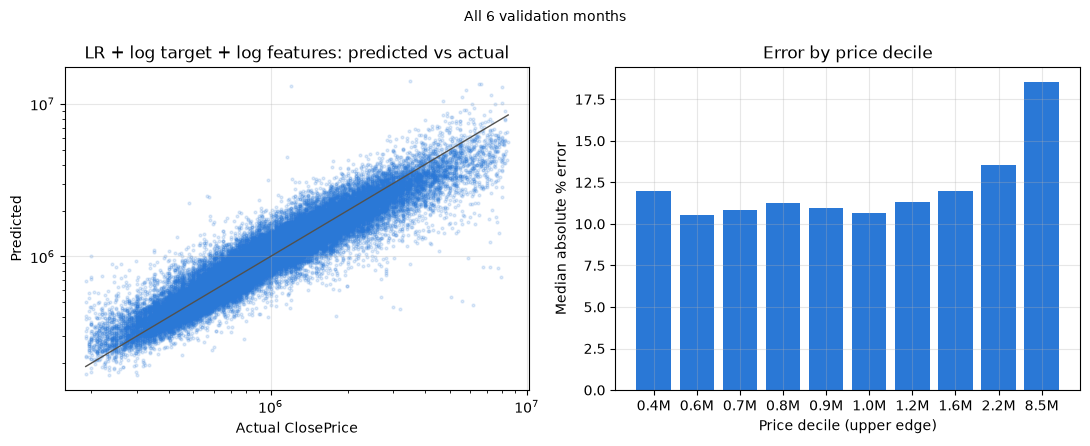

In [9]:
predicted = runs[best_x[baseline_name]][1][[baseline_name]]
actual = df.loc[predicted.index, da.TARGET]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(actual, predicted[baseline_name], s=4, alpha=0.15, color=COLORS[0])
limits = [actual.min(), actual.max()]
axes[0].plot(limits, limits, color="#52514e", linewidth=1)
axes[0].set(xscale="log", yscale="log", xlabel="Actual ClosePrice", ylabel="Predicted",
            title=f"{baseline_name}: predicted vs actual")

price_band = pd.qcut(actual, 10)
error_by_decile = median_ape_by(predicted, actual, price_band)[baseline_name]
axes[1].bar(range(10), error_by_decile.values, color=COLORS[0], width=0.8)
axes[1].set(xticks=range(10), xticklabels=[f"{b.right / 1e6:.1f}M" for b in error_by_decile.index],
            xlabel="Price decile (upper edge)", ylabel="Median absolute % error", title="Error by price decile")
for ax in axes:
    ax.grid(alpha=0.3)
fig.suptitle("All 6 validation months", fontsize=10)
plt.tight_layout()

**Observations**
- **Location dominates.** The ZIP target encoding has the largest coefficient, followed by living area, then coordinates and the city encoding. Bedrooms gets a slightly negative coefficient once living area and bathrooms are in the model, because those features overlap.
- **Errors grow at the extremes.** Over the 6 validation months the median error is about 10.5–12% through the middle of the market and rises to 18.5% in the top decile. Predictions are pulled toward the middle: the cheapest decile is overpredicted by a median 8% and the most expensive underpredicted by 15%. A single linear surface can't bend for the luxury market. That is the main gap the tree models should close.

## 5. Record results

In [10]:
summary.assign(baseline=summary.index == baseline_name).reset_index().to_csv(RESULTS_DIR / "baseline_results.csv", index=False)
results.to_csv(RESULTS_DIR / "baseline_backtest.csv", index=False)
print(f"Baseline: {baseline_name}, X = {best_x[baseline_name]} months, "
      f"validation R² = {summary.loc[baseline_name, 'r2']:.4f}")

Baseline: LR + log target + log features, X = 18 months, validation R² = 0.8007
